# Initiales Datenprofil – Verkehrsunfälle Stadt Zürich

**Ziel:** Die Datengrundlage für F1–F3 prüfen und Regeln für die nächste
Transformation begründen. Dieses Notebook bereinigt keine Rohdaten und führt
noch keine Hypothesentests aus.

Quelle: [Open Data Zürich](https://data.stadt-zuerich.ch/dataset/sid_dav_strassenverkehrsunfallorte),
Datenlieferant: **Bundesamt für Strassen ASTRA**. Definitionen und bekannte
Einschränkungen sind im README dokumentiert. Der lokale Snapshot wird offline
validiert; es erfolgt kein erneuter Download.

Ausführung: Projekt mit `pip install -e ".[dev]"` installieren, den Projekt-Kernel
auswählen und alle Zellen von oben nach unten ausführen. Nur der Bericht und
die Profil-Abbildung werden unter `data/processed/` erzeugt.

In [1]:
import json
import platform
from datetime import UTC, datetime

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from de_projekt import config, ingestion

# Alle Felder zunächst als Text: Codes und führende Nullen bleiben erhalten.
# Keine automatische NA-Erkennung: auch potentielle Marker sollen sichtbar sein.
raw_path = ingestion.run()
raw = pd.read_csv(raw_path, dtype="string", keep_default_na=False, encoding="utf-8-sig")
source = json.loads((raw_path.parent / "source_metadata.json").read_text(encoding="utf-8-sig"))
report = {
    "generated_at": datetime.now(UTC).isoformat(),
    "source_sha256": source["sha256"],
    "source_url": config.SOURCE_URL,
    "rows": len(raw), "columns": len(raw.columns),
    "versions": {"python": platform.python_version(), "pandas": pd.__version__},
}
display(pd.DataFrame({"Kennzahl": ["Zeilen", "Spalten", "Dateigrösse (Bytes)"],
                      "Wert": [len(raw), len(raw.columns), source["bytes"]]}))

,Kennzahl,Wert
0,Zeilen,70767
1,Spalten,36
2,Dateigrösse (Bytes),38710929


## 1. Fehlende Angaben, Datentypen und Duplikate

Leere oder nur aus Leerzeichen bestehende Werte zählen als fehlende Angaben.
Zeichenfolgen wie `unknown` oder `-` werden separat als mögliche Marker
ausgewiesen, nicht automatisch als fehlend interpretiert. Die Code-Tabellen
können weitere fachlich unbekannte Kategorien enthalten.

In [2]:
stripped = raw.apply(lambda column: column.str.strip())
missing = stripped.eq("")
markers = stripped.apply(lambda column: column.str.lower().isin(
    ["na", "n/a", "null", "none", "nan", "unknown", "unbekannt", "-"]
))
inventory = pd.DataFrame({
    "dtype_gelesen": raw.dtypes.astype(str),
    "fehlend": missing.sum(), "moegliche_na_marker": markers.sum(),
    "rand_leerzeichen": raw.ne(stripped).sum(),
    "verschiedene_werte": raw.nunique(),
})
report["column_inventory"] = inventory.reset_index(names="column").to_dict("records")
report["duplicate_rows"] = int(raw.duplicated().sum())
report["duplicate_ids"] = int(raw["AccidentUID"].duplicated().sum())
report["empty_ids"] = int(missing["AccidentUID"].sum())
report["invalid_id_format"] = int((~stripped["AccidentUID"].str.fullmatch(r"[0-9A-Fa-f]{32}")).sum())
display(inventory)
display(pd.Series({key: report[key] for key in
    ["duplicate_rows", "duplicate_ids", "empty_ids", "invalid_id_format"]}))

,dtype_gelesen,fehlend,moegliche_na_marker,rand_leerzeichen,verschiedene_werte
AccidentUID,string,0,0,0,70767
AccidentType,string,0,0,0,11
AccidentType_de,string,0,0,0,11
AccidentType_fr,string,0,0,0,11
AccidentType_it,string,0,0,0,11
AccidentType_en,string,0,0,0,11
AccidentSeverityCategory,string,0,0,0,4
AccidentSeverityCategory_de,string,0,0,0,4
AccidentSeverityCategory_fr,string,0,0,0,4
AccidentSeverityCategory_it,string,0,0,0,4


duplicate_rows       0
duplicate_ids        0
empty_ids            0
invalid_id_format    0
dtype: int64

## 2. Numerische Wertebereiche und räumlicher Bezug

Monat und Stunde müssen ganze Zahlen in ihren dokumentierten Bereichen sein.
Der Katalog nennt 2011–2025; die Jahresprüfung bezieht sich auf diesen Snapshot.
LV95-Koordinaten werden numerisch geprüft und ihr beobachteter Bereich gezeigt.
Eine Bounding-Box allein beweist keine Lage innerhalb der Stadtgrenze.

In [3]:
bounds = {"AccidentYear": (2011, 2025), "AccidentMonth": (1, 12), "AccidentHour": (0, 23)}
numeric = {}
checks = []
for column in [*bounds, "AccidentLocation_CHLV95_E", "AccidentLocation_CHLV95_N"]:
    values = pd.to_numeric(stripped[column], errors="coerce")
    numeric[column] = values
    row = {"column": column, "min": float(values.min()), "max": float(values.max()),
           "non_numeric_nonempty": int((values.isna() & ~missing[column]).sum()),
           "missing": int(missing[column].sum()),
           "non_integer": int((values.notna() & values.mod(1).ne(0)).sum())}
    if column in bounds:
        low, high = bounds[column]
        row["outside_expected_range"] = int((values.notna() & ~values.between(low, high)).sum())
    checks.append(row)
report["numeric_checks"] = checks
report["spatial_codes"] = {column: raw[column].value_counts(dropna=False).to_dict()
                           for column in ["CantonCode", "MunicipalityCode"]}
display(pd.DataFrame(checks))
display(pd.DataFrame(report["spatial_codes"]).fillna(0))

,column,min,max,non_numeric_nonempty,missing,non_integer,outside_expected_range
0,AccidentYear,2011.0,2025.0,0,0,0,0.0
1,AccidentMonth,1.0,12.0,0,0,0,0.0
2,AccidentHour,0.0,23.0,0,0,0,0.0
3,AccidentLocation_CHLV95_E,2677442.0,2689354.0,0,0,0,NaN
4,AccidentLocation_CHLV95_N,1241844.0,1254145.0,0,0,0,NaN


,CantonCode,MunicipalityCode
ZH,70767.0,0.0
0261,0.0,70767.0


## 3. Kategorien und Code-Beschreibungs-Paare

Die Häufigkeitstabellen zeigen die tatsächlich enthaltenen Codes samt deutschen
Beschreibungen. Wir prüfen zusätzlich, ob ein Code mehrere Beschreibungen besitzt.
Die erwarteten Unfalltyp- und Strassenartcodes werden aus den konkreten
Referenzlisten geprüft, bevor Transformation sie verbindlich validiert.

In [4]:
category_columns = ["AccidentType", "AccidentSeverityCategory", "RoadType",
                    "AccidentWeekDay", "AccidentMonth", "AccidentHour"]
report["categories"] = {}
report["inconsistent_code_labels"] = {}
for column in category_columns:
    label = column + "_de"
    columns = [column, label] if label in raw.columns else [column]
    frequencies = raw.groupby(columns, dropna=False).size().reset_index(name="count")
    report["categories"][column] = frequencies.to_dict("records")
    if label in raw.columns:
        count = raw.groupby(column)[label].nunique()
        report["inconsistent_code_labels"][column] = count[count.gt(1)].to_dict()
    print(column)
    display(frequencies)
expected = {"AccidentSeverityCategory": {"as1", "as2", "as3", "as4"},
            "AccidentWeekDay": {f"aw{number}" for number in range(401, 408)}}
report["unexpected_category_codes"] = {
    column: sorted(set(raw[column]) - allowed) for column, allowed in expected.items()
}
display(report["unexpected_category_codes"])

AccidentType


,AccidentType,AccidentType_de,count
0,at0,Schleuder- oder Selbstunfall,18166
1,at00,Andere,667
2,at1,Überholunfall oder Fahrstreifenwechsel,8454
3,at2,Auffahrunfall,11246
4,at3,Abbiegeunfall,4166
5,at4,Einbiegeunfall,3496
6,at5,Überqueren der Fahrbahn,2891
7,at6,Frontalkollision,1070
8,at7,Parkierunfall,17007
9,at8,Fussgängerunfall,3282


AccidentSeverityCategory


,AccidentSeverityCategory,AccidentSeverityCategory_de,count
0,as1,Unfall mit Getöteten,100
1,as2,Unfall mit Schwerverletzten,2897
2,as3,Unfall mit Leichtverletzten,15167
3,as4,Unfall mit Sachschaden,52603


RoadType


...

AccidentMonth

,AccidentMonth,AccidentMonth_de,count
0,1,Januar,4891
1,10,Oktober,6353
2,11,November,6045
3,12,Dezember,5218
4,2,Februar,4636
5,3,März,5776
6,4,April,5643
7,5,Mai,6282
8,6,Juni,6835
9,7,Juli,6504


AccidentHour


,AccidentHour,count
0,00,1197
1,01,822
2,02,661
3,03,494
4,04,527
5,05,720
6,06,1527
7,07,3118
8,08,4143
9,09,3724


{'AccidentSeverityCategory': [], 'AccidentWeekDay': []}

## 4. Beteiligung und Unfallschwere

Die Katalogdefinition spricht bei Beteiligungsmerkmalen von Personenschäden.
Wir prüfen deshalb explizit positive Werte bei `as4` (Sachschaden), anstatt aus
der Definition automatisch falsche Werte zu löschen. Eine Kreuztabelle kann
diese Abweichung belegen, aber ihre Ursache nicht aufklären.

In [5]:
participation = ["AccidentInvolvingPedestrian", "AccidentInvolvingBicycle",
                 "AccidentInvolvingMotorcycle"]
report["participation"] = {}
for column in participation:
    table = pd.crosstab(raw["AccidentSeverityCategory"], raw[column], dropna=False)
    report["participation"][column] = {
        "values": raw[column].value_counts(dropna=False).to_dict(),
        "unexpected_values": sorted(set(raw[column]) - {"true", "false"}),
        "property_damage_true": int((raw["AccidentSeverityCategory"].eq("as4")
                                      & raw[column].eq("true")).sum()),
        "severity_counts": table.reset_index().to_dict("records"),
    }
    print(column)
    display(table)
n_positive = raw[participation].eq("true").sum(axis=1)
report["multiple_participation_rows"] = int(n_positive.ge(2).sum())
report["positive_participation_count_distribution"] = {
    str(key): int(value) for key, value in n_positive.value_counts().sort_index().items()
}
display(n_positive.value_counts().sort_index().rename("Unfälle je Anzahl positiver Merkmale"))
# Jahrestabelle erleichtert später die Prüfung eines möglichen Erfassungswechsels.
property_rows = raw.loc[raw["AccidentSeverityCategory"].eq("as4")]
property_by_year = property_rows[participation].eq("true").groupby(property_rows["AccidentYear"]).sum()
display(property_by_year)
report["property_damage_participation_by_year"] = property_by_year.reset_index().to_dict("records")

AccidentInvolvingPedestrian


AccidentInvolvingPedestrian,false,true
AccidentSeverityCategory,,
as1,46,54
as2,2203,694
as3,12721,2446
as4,52434,169


AccidentInvolvingBicycle


AccidentInvolvingBicycle,false,true
AccidentSeverityCategory,,
as1,78,22
as2,1603,1294
as3,9342,5825
as4,50991,1612


AccidentInvolvingMotorcycle


AccidentInvolvingMotorcycle,false,true
AccidentSeverityCategory,,
as1,89,11
as2,2360,537
as3,12883,2284
as4,50826,1777


0    54845
1    15119
2      803
Name: Unfälle je Anzahl positiver Merkmale, dtype: Int64

,AccidentInvolvingPedestrian,AccidentInvolvingBicycle,AccidentInvolvingMotorcycle
AccidentYear,,,
2011,6,55,46
2012,7,42,53
2013,3,52,60
2014,13,61,57
2015,18,94,122
2016,13,112,135
2017,16,139,142
2018,11,134,134
2019,7,127,134


## 5. Zeitliche Abdeckung und Jahreszusammensetzung

Wir prüfen, ob alle zwölf Monate pro Jahr vertreten sind. Das ist ein
Plausibilitätscheck, kein Beweis einer vollständigen Erfassung aller Tage.
Ein exaktes Unfall-Datum ist im Snapshot nicht enthalten. Der Wechsel der
Sachschadenmeldung am 1. Juli 2015 wird in der Abbildung markiert.

AccidentMonth,1,2,3,4,5,6,7,8,9,10,11,12
AccidentYear,,,,,,,,,,,,
2011,259,206,263,304,334,287,271,314,310,299,279,294
2012,245,221,307,261,291,289,288,287,254,257,297,254
2013,221,207,273,279,313,344,316,300,274,299,299,250
2014,233,245,300,281,296,356,268,280,281,295,231,227
2015,230,225,287,267,307,338,524,473,491,475,490,422
2016,430,381,395,495,516,529,459,487,522,489,467,386
2017,389,378,517,432,517,514,467,475,459,471,493,436
2018,388,316,494,511,500,547,548,502,459,512,485,415
2019,380,396,456,440,471,563,513,476,480,483,483,387


AccidentSeverityCategory,as1,as2,as3,as4,total,person_injury
AccidentYear,,,,,,
2011,11,197,864,2348,3420,1072
2012,6,223,851,2171,3251,1080
2013,9,230,801,2335,3375,1040
2014,4,194,866,2229,3293,1064
2015,6,180,1006,3337,4529,1192
2016,7,211,1044,4294,5556,1262
2017,5,239,994,4310,5548,1238
2018,10,211,1058,4398,5677,1279
2019,6,182,1107,4233,5528,1295


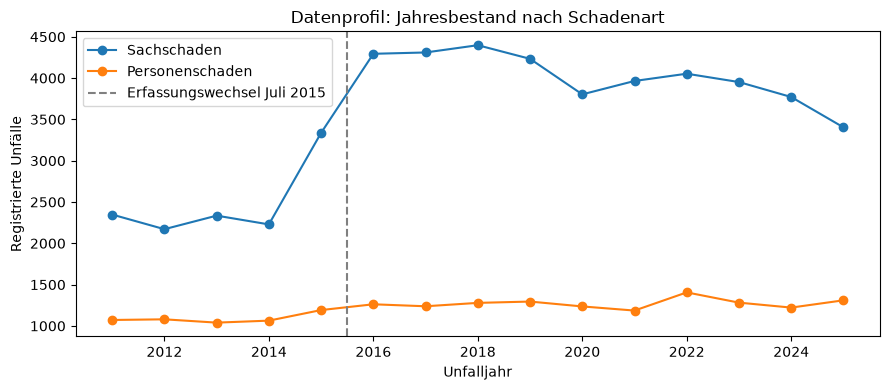

In [6]:
year_values = numeric["AccidentYear"].astype("Int64")
month_values = numeric["AccidentMonth"].astype("Int64")
months = pd.crosstab(year_values, month_values).reindex(
    index=range(2011, 2026), columns=range(1, 13), fill_value=0
)
annual = pd.crosstab(year_values, raw["AccidentSeverityCategory"]).reindex(
    index=range(2011, 2026), columns=["as1", "as2", "as3", "as4"], fill_value=0
)
annual["total"] = annual.sum(axis=1)
annual["person_injury"] = annual[["as1", "as2", "as3"]].sum(axis=1)
report["annual_counts"] = annual.rename_axis("year").reset_index().to_dict("records")
report["year_month_counts"] = months.rename_axis("year").reset_index().to_dict("records")
report["zero_count_year_months"] = int(months.eq(0).sum().sum())
display(months)
display(annual)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(annual.index, annual["as4"], marker="o", label="Sachschaden")
ax.plot(annual.index, annual["person_injury"], marker="o", label="Personenschaden")
ax.axvline(2015.5, color="grey", linestyle="--", label="Erfassungswechsel Juli 2015")
ax.set(xlabel="Unfalljahr", ylabel="Registrierte Unfälle", title="Datenprofil: Jahresbestand nach Schadenart")
ax.legend()
fig.tight_layout()
config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
figure_path = config.PROCESSED_DIR / "profile_annual_counts.png"
fig.savefig(figure_path, dpi=150)
plt.show()

## 6. Bericht und nächste Entscheidungen

Der Bericht ist ein Profil des unveränderten Snapshots, kein Bereinigungsbericht.
Er enthält die Quellenprüfsumme, damit spätere Transformationen auf denselben
Bestand zurückgeführt werden können. Die ausführlichen Tabellen oben dienen
als überprüfbare Grundlage für die im README festgehaltenen Entscheidungen.

In [7]:
report_path = config.PROCESSED_DIR / "data_profile.json"
report_path.write_text(json.dumps(report, ensure_ascii=False, indent=2, allow_nan=False)
                       + "\n", encoding="utf-8")
# Rohdaten auch nach der Notebook-Ausführung unverändert und gültig.
ingestion.validate_snapshot(raw_path.parent)
print(f"Profilbericht: {report_path}")
print(f"Abbildung: {figure_path}")

Profilbericht: C:\Users\issaf\OneDrive\Dokumente\ZHAW\Semester 5\Data Engineering\Projekt\de_projektarbeit_hs_2026_zhaw\data\processed\data_profile.json
Abbildung: C:\Users\issaf\OneDrive\Dokumente\ZHAW\Semester 5\Data Engineering\Projekt\de_projektarbeit_hs_2026_zhaw\data\processed\profile_annual_counts.png


**Konsequenzen für die nächste Transformation:**

- Datentypen explizit festlegen; Codes nicht mit ihren Beschreibungstexten verwechseln.
- Originaldaten erhalten und keine pauschale Entfernung von Zeilen vornehmen.
- Boolesche Merkmale explizit aus `true`/`false` ableiten; andere Angaben bleiben unbekannt.
- Überlappende Beteiligungsmerkmale getrennt behandeln; ein Unfall kann mehrere besitzen.
- Den Erfassungswechsel 2015 in F3 berücksichtigen. Belegte Monatsabdeckung erlaubt
  keine Behauptung, dass jeder Kalendertag vollständig erfasst wurde.
- H2 zunächst auf Personenschäden abgrenzen und die verbleibende Semantik-Unklarheit
  ausdrücklich berichten. Daten allein entscheiden nicht, welche Definition korrekt ist.
- Die fachlichen Befunde werden im README zusammengefasst. Hypothesentests und
  Antworten auf die Forschungsfragen folgen nach Bereinigung und SQLite-Speicherung.